# 거울아 거울아, 나는 멍멍이 상이니, 아니면 냥이 상이니?

## 1-2. 내가 직접 만드는 강아지 고양이 분류기 (1) 이미지 분류 문제

In [1]:
import tensorflow as tf
print(tf.__version__) # 설치된 텐서플로우의 버전 확인

2.6.0


### 모델 학습을 위한 데이터셋(dataset) 준비하기

강아지와 고양이 이미지 데이터가 필요하므로 텐서플로우에서 제공하는 데이터셋을 사용한다.

클라우드 사용자는 tensorflow_datasets 패키지가 이미 설치되어 있으므로 바로 패키지를 로드한다.

In [2]:
import tensorflow_datasets as tfds

tfds.__version__

'4.4.0'

tensorflow_datasets는 텐서플로우가 제공하는 데이터셋 모음집이다. 우리에게 필요한 강아지와 고양이 이미지뿐만 아니라 음성 데이터셋, 이미지 데이터셋, 텍스트 데이터셋 등 방대한 종류의 데이터셋을 제공한다.

In [3]:
!mkdir -p ~/aiffel/cats_vs_dogs/PetImages
!ln -s ~/data/* ~/aiffel/cats_vs_dogs/

ln: failed to create symbolic link '/aiffel/aiffel/cats_vs_dogs/cat_face.jpg': File exists
ln: failed to create symbolic link '/aiffel/aiffel/cats_vs_dogs/cats_vs_dogs': File exists
ln: failed to create symbolic link '/aiffel/aiffel/cats_vs_dogs/my_cat.jpg': File exists
ln: failed to create symbolic link '/aiffel/aiffel/cats_vs_dogs/my_dog.jpg': File exists


In [4]:
(raw_train, raw_validation, raw_test), metadata = tfds.load( # metadata: 데이터셋의 정보를 담고 있는 메타데이터를 의미, 이 정보에는 데이터셋의 특성이나 클래스 등에 관한 정보가 포함
    name='cats_vs_dogs', # 불러올 데이터셋
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'], # 전체 'train' 데이터셋을 80%, 10%, 10%의 비율로 훈련, 검증, 테스트로 나눈다
    data_dir='~/aiffel/cats_vs_dogs/', # 저장할 디렉토리를 지정
    download=False, # 데이터를 다운로드하지 않고 로컬에서 불러오도록 설정
    with_info=True, # 데이터셋의 정보(metadata)도 함께 불러오도록 설정
    as_supervised=True, # 데이터를 (입력, 레이블) 형태로 불러온다.
)

In [5]:
# 데이터셋 확인하기
print(raw_train)
print(raw_validation)
print(raw_test)

<PrefetchDataset shapes: ((None, None, 3), ()), types: (tf.uint8, tf.int64)>
<PrefetchDataset shapes: ((None, None, 3), ()), types: (tf.uint8, tf.int64)>
<PrefetchDataset shapes: ((None, None, 3), ()), types: (tf.uint8, tf.int64)>


각 데이터셋의 형태가 잘 출력되었다.

* 모든 데이터셋은 (image, label)의 형태를 가진다. ((None, None, 3), ())가 이를 나타낸다. 여기에서 앞에 있는 (None, None, 3)은 image의 shape를, 뒤의 ()는 정답 카테고리인 label의 shape를 의미한다.
* 이미지는 (height, width, channel)로 3차원 데이터이기 때문에 (None, None, 3)과 같이 나타났다. 이때 height와 width가 None으로 나타난 이유는 **모든 이미지의 크기가 전부 다르기 때문이다. 정해져 있지 않은 사이즈이기 때문에 None으로 나타낸 것이다.**
* 3이라는 숫자는 이미지의 색을 표현하는 채널의 수를 나타낸다. 컬러 이미지의 경우, 색은 RGB의 세 가지 색 조합으로 나타낼 수 있다는 것을 알고 있는 것처럼 이미지를 컴퓨터상에 나타낼 때, 각 픽셀(pixel)의 색은 RGB의 세 가지 색의 조합으로 나타나기 때문에 컬러 이미지는 항상 3개의 채널을 가지고 있어야 한다. 반면, 흑백 이미지는 white/black만 나타내면 되므로 단 하나의 채널만 있어도 충분하다.
* label은 특정 이미지가 강아지인지, 혹은 고양이인지를 나타내는 단일 값이다. 단순히 1차원의 숫자 하나로 표현될 수 있기 때문에 차원이 따로 나타나지 않는다.

### 데이터 시각화를 통해 확인하고, 모델에 입력할 수 잇는 형태로 전처리하기

In [6]:
# 데이터 확인을 위해 matplotlib 라이브러리 가져오기
import matplotlib.pyplot as plt
%matplotlib inline # Jupyter Notebook이나 Jupyter Lab 등에서 Matplotlib으로 생성된 그림을 노트북 내에서 바로 볼 수 있도록 하는 명령어
%config InlineBackend.figure_format = 'retina' # 레티나 디스플레이를 지원하는 환경에서는 고해상도 그림을 출력하기 위한 설정

print("슝~")

슝~


raw_train 안에 있는 데이터를 확인해 보기 위해 tf.data.Dataset에서 제공하는 take라는 함수를 사용해 보자. 이 함수는 인수로 받은 만큼의 개수만큼의 데이터를 추출하여 새로운 데이터셋 인스턴스를 생성하여 리턴하는 함수이다.

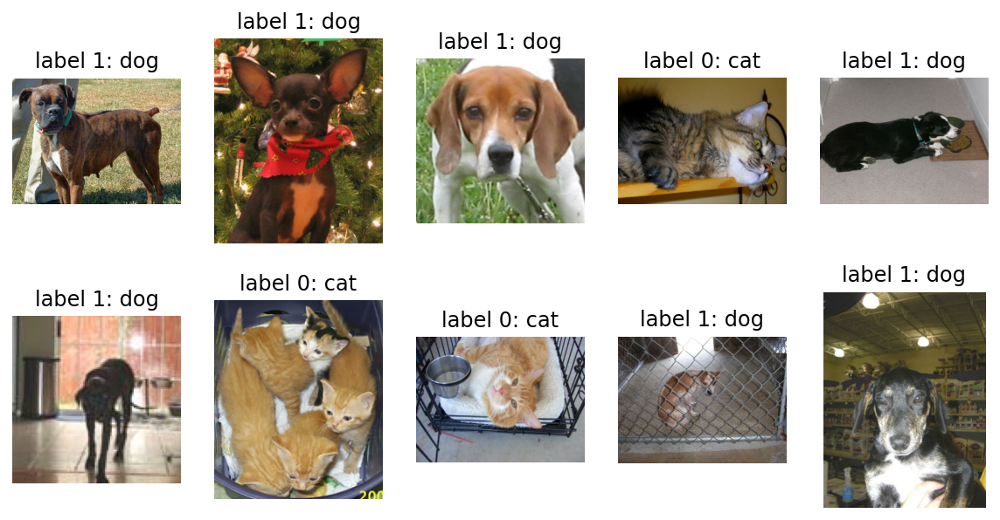

In [7]:
plt.figure(figsize=(10, 5))

get_label_name = metadata.features['label'].int2str # 데이터셋의 메타데이터에서 레이블 정보를 활용하여 숫자 형태의 레이블을 해당하는 이름으로 변환하는 함수

for idx, (image, label) in enumerate(raw_train.take(10)): # 10개의 데이터를 가져온다
    plt.subplot(2, 5, idx+1)
    plt.imshow(image)
    plt.title(f'label {label}: {get_label_name(label)}')
    plt.axis('off')

* 10장의 사진을 확인해 보니 귀여운 강아지와 고양이 이미지들이 잘 섞여 있다.
* 강아지는 label 1로, 고양이는 label 0으로 설정되어 있는 것을 확인할 수 있다.. 앞서 설명했듯 이미지의 사이즈는 전부 제각각이므로 모델을 학습시킬 때에는 이미지 사이즈를 통일시켜 주는 작업을 해야할 것 같다.
* format_example() 함수를 이용해 이미지를 같은 포맷으로 통일 시켜 보자
* 아래 코드는 이미지의 사이즈를 160x160 픽셀로 통일시킬 뿐만 아니라, 각 픽셀값의 scale을 수정해주는 역할도 한다.

**‍🌈 간단 상식 - 타입캐스팅(Type Casting)**

형변환이라고도 불리는 타입개스팅은 다른 데이터 타입으로 형(타입)을 바꿔주는 것을 의미한다. 정수형을 실수형으로 바꾸기 위해 float()를 사용하는 것이 타입캐스팅의 한 예이다.

In [14]:
IMG_SIZE = 160 # 리사이징할 이미지의 크기

def format_example(image, label):
    image = tf.cast(image, tf.float32) # image=float(image)같은 타입캐스팅의 텐서플로우 버전
    image = (image/127.5) - 1 # 픽셀값의 scale 수정
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, label

print("슝~")

슝~


**픽셀 값의 범위는 0 ~ 255 사이의 값들을 그 중간값인 127.5로 나누고 1을 뺐으므로, -1 ~ 1 사이의 실수값이 된다.**

format_example() 함수를 raw_train, raw_validation, raw_test 에 map() 함수로 적용시켜서 원하는 모양의 train, validataion, test 데이터셋으로 변환해 보자. 리스트 원소 전체에 동일한 변환 함수를 for 문을 사용하지 않고 손쉽게 적용하게 해주는 map 함수에 대해서 빠르게 아래 코드로 알아보자.

map은 리스트의 요소를 지정된 함수로 처리해주는 함수입니다.

In [9]:
a = [1.2, 2.5, 3.7, 4.6]
a = list(map(int, a)) # 리스트의 요소를 정수로 변환하여 리스트로 생성
a

[1, 2, 3, 4]

In [11]:
# Q. map함수를 사용해서 0~9까지 숫자를 문자열(str을 사용)로 변환하여 리스트로 출력
b = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
b = list(map(str, b))
b

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

In [12]:
# Q. map함수를 사용해서 0~9까지 숫자를 문자열(str을 사용)로 변환하여 리스트로 출력(range 이용)
numbers = list(map(str, range(10)))
numbers

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

In [15]:
train = raw_train.map(format_example) # format_example은 이미지 resize 함수
validation = raw_validation.map(format_example)
test = raw_test.map(format_example)

print(train)
print(validation)
print(test)

<MapDataset shapes: ((160, 160, 3), ()), types: (tf.float32, tf.int64)>
<MapDataset shapes: ((160, 160, 3), ()), types: (tf.float32, tf.int64)>
<MapDataset shapes: ((160, 160, 3), ()), types: (tf.float32, tf.int64)>


IMG_SIZE를 160으로 지정해 줌으로써, 모든 이미지의 크기를 (160, 160, 3)으로 통일

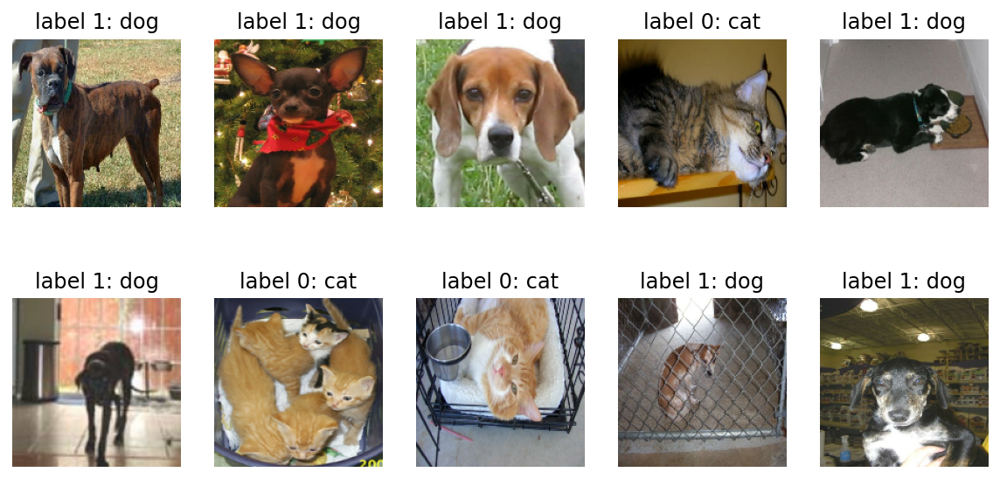

In [17]:
# 다시 이미지를 시각적으로 확인해 보자
plt.figure(figsize=(10, 5))

get_label_name = metadata.features['label'].int2str

for idx, (image, label) in enumerate(train.take(10)):
    plt.subplot(2, 5, idx +1)
    image = (image + 1) / 2 # matplotlib으로 이미지를 시각화 할 경우에는 모든 픽셀값이 양수여야 하므로, 
                            # -1~1 사이의 픽셀값을 1을 더한 후 2로 나눠서 0~1 사이의 값으로 변환
    plt.imshow(image)
    plt.title(f'label {label}: {get_label_name(label)}')
    plt.axis('off')

다시 이미지를 시각적으로 확인해 다시 확인해 보니 모든 이미지의 크기가 균일해진 것을 확인할 수 있다.

### 텐서플로우를 활용해 모델 구조 설계하기

In [19]:
# 모델 생성에 필요한 함수들을 불러오기
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, MaxPooling2D

print("슝~")

슝~


* models는 모델 그 자체를 구축하기 위한 함수들을 포함하고 있다.
* layers에는 모델의 구성 요소인 여러 가지 종류의 레이어(layer), 즉 "층"이라는 함수들을 가지고 있다. 
* Sequential은 말 그대로 "연속적인" 모델을 쌓기 위한 함수이다. Sequential 함수 안에 연속적으로 여러 가지 레이어들이 들어간다.

In [23]:
# 모델 만들기
model = Sequential([
    Conv2D(filters=16, kernel_size=3, padding="same", activation='relu', input_shape=(160, 160, 3)),
    MaxPooling2D(),
    Conv2D(filters=32, kernel_size=3, padding="same", activation='relu'),
    MaxPooling2D(),
    Conv2D(filters=64, kernel_size=3, padding="same", activation='relu'),
    MaxPooling2D(),
    Flatten(),
    Dense(units=512, activation='relu'),
    Dense(units=2, activation='softmax')
])

print("슝~")

슝~


In [24]:
# 모델 전체 구조를 summary로 확인
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_6 (Conv2D)            (None, 160, 160, 16)      448       
_________________________________________________________________
max_pooling2d_6 (MaxPooling2 (None, 80, 80, 16)        0         
_________________________________________________________________
conv2d_7 (Conv2D)            (None, 80, 80, 32)        4640      
_________________________________________________________________
max_pooling2d_7 (MaxPooling2 (None, 40, 40, 32)        0         
_________________________________________________________________
conv2d_8 (Conv2D)            (None, 40, 40, 64)        18496     
_________________________________________________________________
max_pooling2d_8 (MaxPooling2 (None, 20, 20, 64)        0         
_________________________________________________________________
flatten_2 (Flatten)          (None, 25600)             0

summary를 확인해 보면 height와 width는 160 → 80 → 40 → 20 으로 점점 작아지고, channel은 16 → 32 → 64까지 커지고 있다.

* 첫 번째 차원은 데이터의 개수를 나타낸다. 여기서는 정해지지 않은 수라는 None 기호로 표시되었다. None은 배치(batch) 사이즈에 따라 모델에 다른 수의 입력이 들어올 수 있음을 나타냅니다.

* 데이터 하나의 크기는 (height, width, channel)로 3차원이다. 6개의 레이어를 지나면서 height와 width는 점점 작아지고, channel은 점점 커지다가, flatten 계층을 만나 25,600(20x20x64)이라는 하나의 숫자로, 즉 1차원으로 shape가 줄어든다.

* 앞의 모델과 같이 점점 작은 feature map이 출력되다가, Flatten과 Dense 레이어를 거쳐 데이터가 1차원으로 줄어드는 네트워크는 CNN(Convolutional Neural Net)을 사용한 딥러닝 모델의 가장 대표적인 형태이다.

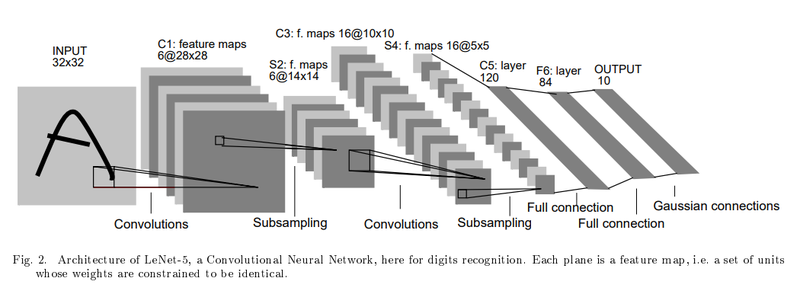

맨 왼쪽처럼 이미지 한 장이 입력되면 그 이미지는 Convolutional(합성곱) 연산을 통해 그 형태가 점점 길쭉해지다가, Flatten 레이어를 만나면 오른쪽처럼 한 줄로 펴진다. 3차원의 이미지를 1차원 으로 펼치는 것이다.

Flatten을 조금 더 직관적으로 이해하기 위해 배열을 다루기 용이한 numpy를 활용해 보자.

In [25]:
import numpy as np
image = np.array([[1, 2], [3, 4]])
print(image.shape)
image

(2, 2)


array([[1, 2],
       [3, 4]])

In [26]:
# (2, 2) 크기의 이미지를 flatten시키면?
image.flatten()

array([1, 2, 3, 4])

모든 숫자를 일렬로 편 상태로 나타나게 된다. 모델에서 flatten 레이어를 통과한다는 것도 위와 같이 모든 숫자를 일렬로 펼쳐놓는 것 과 같다.

그 후 Dense 레이어에서 512개의 노드로 축소시켜 최종 출력은 단 두 개의 숫자로 구성된 하나의 확률분포를 내뱉게 되고, 이 두 숫자는 각각 입력된 이미지가 강아지일 확률과 고양이인 확률을 의미하게 된다.

정리해 보자면, 딥러닝 모델은 (160, 160, 3) 크기의 3차원 이미지를 입력받아 여러 레이어를 거치며 형태를 바꾸다가 최종적으로는 몇 개의 숫자를 출력해내는 함수라고 할 수 있다.

모델이 여기에서 어떻게 학습을 하며 어떻게 강아지와 고양이를 구별해낼 수 있는지는, 앞으로 점차 이론 내용들을 공부하며 알아보자.

### 모델 compile 완료 후 학습시키기

* 학습률(learning_rate)이라는 파라미터를 0.0001로 설정
* 모델을 compile 하여 학습할 수 있는 형태로 변환

In [28]:
learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=learning_rate), 
              loss=tf.keras.losses.sparse_categorical_crossentropy,
              metrics=['accuracy'])

print("슝~")

슝~


**compile 하기 위해 필요한 세 가지**

* optimizer는 학습을 어떤 방식으로 시킬 것인지 결정한다. 어떻게 최적화시킬 것인지를 결정하기 때문에 최적화 함수라고 부르기도 한다.
* loss는 모델이 학습해나가야 하는 방향을 결정한다. 이 문제에서는 모델의 출력은 입력받은 이미지가 고양이인지 강아지인지에 대한 확률분포로 두었으므로, 입력 이미지가 고양이(label=0)일 경우 모델의 출력이 [1.0, 0.0]에 가깝도록, 강아지(label=1)일 경우 [0.0, 1.0]에 가까워지도록 하는 방향을 제시한다.
* metrics는 모델의 성능을 평가하는 척도이다. 분류 문제를 풀 때, 성능을 평가할 수 있는 지표는 정확도(accuracy), 정밀도(precision), 재현율(recall) 등이 있다. 여기서는 정확도를 사용했다.

성능 평가 지표에 대한 자세한 내용 링크: https://sumniya.tistory.com/26

**Q.Accuracy는 어떻게 계산되는 것일까? 그리고 Accuracy가 높다고 항상 좋은 것일까?**

모든 경우의 수에서 정답(True ⇒ True, False ⇒ False)을 맞춘 확률이다.

Accuracy = (TP + TN) / (TP + FN + FP + TN)

만약 데이터가 불균형하다고 한다면, 한 가지에 대해서만 잘 맞추게 되면서 Accuracy가 높아도 좋지 않은 상황이 있을 수 있다. 그래서 Precision이나 Recall, F1 score 등의 지표로 보완한다.

In [29]:
# 한 스텝에 학습시킬 데이터의 개수: BATCH_SIZE, 학습 데이터를 적절히 섞어줄 SHUFFLE_BUFFER_SIZE를 설정
BATCH_SIZE = 32
SHUFFLE_BUFFER_SIZE = 1000
print("슝~")

슝~



SHUFFLE_BUFFER_SIZE = 1000에서의 1000은 데이터셋을 섞을 때 사용되는 버퍼의 크기를 의미합니다.

기계 학습에서 데이터를 훈련하기 전에 종종 데이터를 섞는데, 이는 모델이 데이터의 순서나 패턴에 영향을 받지 않도록 하기 위함입니다. 예를 들어, 데이터셋이 특정한 순서로 정렬되어 있을 경우 모델이 그 순서를 학습하는 경우가 발생할 수 있습니다. 이를 방지하기 위해 데이터를 랜덤하게 섞는 것이 일반적입니다.

버퍼의 크기는 데이터를 섞을 때 사용되는 단위 크기를 나타냅니다. 더 큰 버퍼 크기는 보다 랜덤한 샘플링을 제공하지만, 메모리를 더 많이 사용할 수 있습니다. 적절한 버퍼 크기를 선택하는 것은 성능과 메모리 사용 사이의 트레이드 오프에 관련된 문제입니다. 1000이라는 값은 섞기에 사용되는 상대적으로 중간 정도의 버퍼 크기일 수 있습니다.

BATCH_SIZE에 따라 32개의 데이터를 랜덤으로 뿌려줄 train_batches, validation_batches, test_batches를 만들어 준다. train_batches는 모델이 끊임없이 학습될 수 있도록 전체 데이터에서 32개를 랜덤으로 뽑아 계속 제공해 줄 것이다.

In [33]:
train_batches = train.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
validation_batches = validation.batch(BATCH_SIZE)
test_batches = test.batch(BATCH_SIZE)
print("슝~")

슝~


In [32]:
# train_batches에서 하나의 batch만 꺼내 데이터를 확인
for image_batch, label_batch in train_batches.take(1):
    break
    
image_batch.shape, label_batch.shape

(TensorShape([32, 160, 160, 3]), TensorShape([32]))

**take() 함수**

take() 함수는 데이터셋에서 일부 데이터를 추출하는 데 사용되는 함수입니다. 이 함수는 데이터셋에서 지정된 개수만큼의 요소를 가져올 수 있게 해줍니다.

예를 들어, dataset.take(5)는 데이터셋에서 처음 5개의 요소를 가져옵니다. 이때, 데이터셋의 처음부터 5개의 요소를 추출하여 새로운 데이터셋을 만들어 반환합니다.

주로 딥러닝에서는 데이터셋이 클 때 전체 데이터를 한 번에 처리하기보다는 작은 배치(batch)로 나누어 학습시키는 것이 일반적입니다. 따라서 take() 함수를 사용하여 데이터셋에서 일부 배치를 가져와서 확인하거나, 해당 배치를 사용하여 모델을 학습시킬 수 있습니다.

본격적으로 모델을 학습시켜보기 전에, 초기 모델의 성능은 어떤지 확인해 보자. validation(검증)을 하기 위한 데이터셋인 validation_batches를 이용해 20번의 예측을 해 보고, 평균 loss와 평균 accuracy를 확인해 보자.

In [35]:
validation_steps = 20
loss0, accuracy0 = model.evaluate(validation_batches, steps=validation_steps)

print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2}".format(accuracy0))

10/20 [==============>...............] - ETA: 0s - loss: 0.6951 - accuracy: 0.4906

Corrupt JPEG data: 162 extraneous bytes before marker 0xd9


20/20 [==============================] - 1s 31ms/step - loss: 0.6958 - accuracy: 0.4812
initial loss: 0.70
initial accuracy: 0.48


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


* model.evaluate(validation_batches, steps=validation_steps): evaluate() 함수를 사용하여 모델을 검증 데이터셋(validation_batches)을 통해 평가합니다. 여기서 steps=validation_steps는 검증 단계의 수를 지정합니다. 이는 검증 데이터셋을 몇 번 반복할지를 결정하는데, 한 번의 에포크(epoch) 동안 이 수만큼의 배치를 사용하여 평가합니다. 이 경우에는 20개의 검증 단계를 수행합니다.

* loss0, accuracy0 = model.evaluate(validation_batches, steps=validation_steps): 검증 단계를 수행한 결과인 손실(loss)과 정확도(accuracy)를 변수 loss0와 accuracy0에 저장합니다.

* print("initial loss: {:.2f}".format(loss0)): 초기 손실값을 출력합니다. 여기서 {:.2f}는 소수점 두 자리까지만 출력하도록 포맷을 지정하는 것입니다.

* print("initial accuracy: {:.2f}".format(accuracy0)): 초기 정확도를 출력합니다. 마찬가지로 {:.2f}를 사용하여 소수점 두 자리까지만 출력하도록 포맷을 지정합니다.

이 코드는 모델을 처음 평가하고, 해당 검증 데이터셋에 대한 초기 손실과 정확도를 출력하여 모델의 초기 성능을 파악하는 데 사용됩니다.

loss는 0.7이, accuracy는 약 50%가 나왔다.

* 여기서 loss는 말 그대로 "손실"이라는 뜻으로, 얼마나 모델이 틀렸는지 나타낸다. 따라서 loss는 낮을수록 좋은 것이다.
* accuracy는 몇 퍼센트의 정확도를 보이느냐 에 대한 수치이다. 우리는 강아지와 고양이를 분류하려고 하는데, 두 장 중 하나를 찍어도 50%는 나올 테니 지금 모델은 전혀 의미 없는 예측을 하는 것이라고 할 수 있다.

In [38]:
# 모델 학습시키기
EPOCHS = 10
history = model.fit(train_batches, 
                    epochs=EPOCHS,
                    validation_data=validation_batches)

Epoch 1/10
168/582 [=======>......................] - ETA: 32s - loss: 0.7160 - accuracy: 0.5751

Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


200/582 [=========>....................] - ETA: 30s - loss: 0.7016 - accuracy: 0.5853

210/582 [=========>....................] - ETA: 29s - loss: 0.6985 - accuracy: 0.5868

Corrupt JPEG data: 396 extraneous bytes before marker 0xd9


282/582 [=============>................] - ETA: 23s - loss: 0.6786 - accuracy: 0.6025

... (181 outputs left out)

Corrupt JPEG data: 228 extraneous bytes before marker 0xd9


582/582 [==============================] - ETA: 0s - loss: 0.0954 - accuracy: 0.9703

Corrupt JPEG data: 162 extraneous bytes before marker 0xd9
Corrupt JPEG data: 252 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


582/582 [==============================] - 39s 65ms/step - loss: 0.0954 - accuracy: 0.9703 - val_loss: 0.6415 - val_accuracy: 0.7786


### 모델 학습곡선 확인 및 예측 결과 시각화하기

* 첫 번째 accuracy는 훈련 데이터셋에 대한 정확도이다. 학습하고 있는 데이터에 대한 정확도이다.
* 두 번째 val_accuracy는 검증 데이터셋에 대한 정확도이다. 학습하지 않고 있는, 즉 해당 학습 단계에서 보지 않은 데이터에 대한 정확도이다.

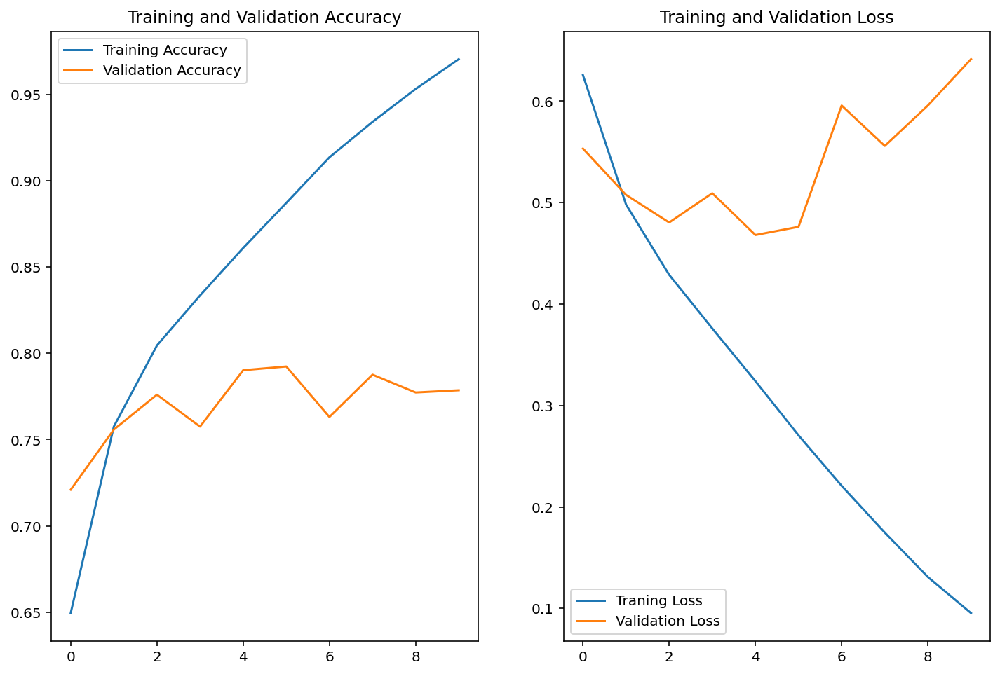

In [42]:
# 학습 단계에 따른 정확도 변화를 그래프로 확인해 보자.
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(EPOCHS)

plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Traning Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title("Training and Validation Loss")
plt.show()

training accuracy는 10 epoch를 진행하는 동안 꾸준히 증가한다. 마지막에는 거의 90%를 넘어서는 수치를 보인다.
반면, validation accuracy는 초반에 75%~80% 사이까지는 증가하지만 증가폭이 training dataset에 비해 매우 적고, 증가하는 양상도 불안정하다.
training accuracy는 현재 학습하는 데이터셋에 대한 정확도이기 때문에 모델의 구조나 데이터셋 등에 문제가 없다면 일반적으로 학습하면 할수록 꾸준히 계속 오른다. 반면 validation accuracy는 학습하지 않은 데이터셋에 대한 정확도이기 때문에 일정수준까지 오른 후에는 계속 오를지 장담할 수 없다. -> **과적합의 모습을 보이고 있다.**

In [43]:
# 모델 예측 결과를 확인
for image_batch, label_batch in test_batches.take(1):
    images = image_batch
    labels = label_batch
    predictions = model.predict(image_batch)
    break
    
predictions

array([[9.9987757e-01, 1.2244517e-04],
       [9.8537350e-01, 1.4626469e-02],
       [3.7017785e-02, 9.6298218e-01],
       [9.9999726e-01, 2.6889659e-06],
       [9.6400529e-01, 3.5994790e-02],
       [3.2911935e-01, 6.7088068e-01],
       [5.8689592e-03, 9.9413103e-01],
       [9.9381083e-01, 6.1892406e-03],
       [4.2783707e-02, 9.5721626e-01],
       [4.8121482e-02, 9.5187849e-01],
       [1.3424706e-02, 9.8657531e-01],
       [9.9996185e-01, 3.8117862e-05],
       [9.4561893e-01, 5.4381046e-02],
       [4.0334264e-05, 9.9995971e-01],
       [9.9732047e-01, 2.6795391e-03],
       [9.9972206e-01, 2.7789953e-04],
       [7.6400930e-01, 2.3599073e-01],
       [3.0377116e-05, 9.9996960e-01],
       [9.4509828e-01, 5.4901738e-02],
       [9.4695997e-01, 5.3040061e-02],
       [9.8256463e-01, 1.7435392e-02],
       [8.5375386e-01, 1.4624617e-01],
       [9.8121476e-01, 1.8785218e-02],
       [9.8342967e-01, 1.6570270e-02],
       [8.5086101e-01, 1.4913902e-01],
       [9.8175541e-02, 9.

predictions가 엄청난 소수점 값들로 이루어져 있다. 이 값은 모델이 판단한 [고양이일 확률, 강아지의 확률]인데, [1.0, 0.0]에 가까울수록 label이 0인 고양이로, [0.0, 1.0]에 가까울수록 label이 1인 강아지로 예측했다고 볼 수 있다.

즉 고양이일 확률이 더 높으면 고양이로, 그렇지 않으면 강아지로 예측했다고 할 수 있겠다.

prediction 값들을 실제 추론한 라벨(고양이:0, 강아지:1)로 변환해 보자. 실제로 모델이 각 이미지를 강아지라고 판단했는지, 고양이로 판단했는지 보기 위해서!

In [44]:
predictions = np.argmax(predictions, axis=1)
predictions

array([0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 1])

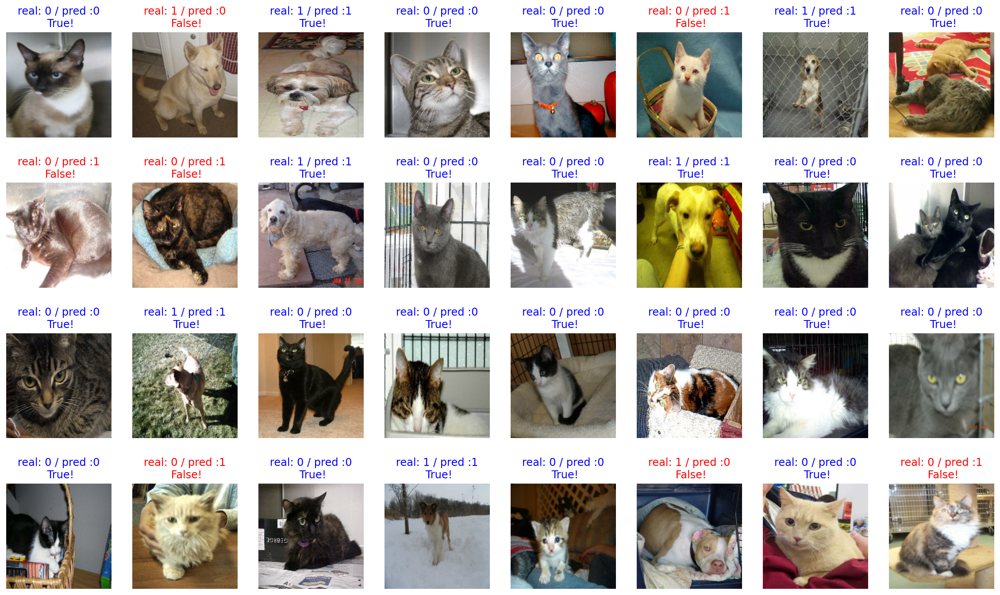

In [45]:
# 32장의 image들과 32개의 label, 32개의 prediction 각각을 시각화
plt.figure(figsize=(20, 12))

for idx, (image, label, prediction) in enumerate(zip(images, labels, predictions)):
    plt.subplot(4, 8, idx+1)
    image = (image + 1) / 2
    plt.imshow(image)
    correct = label == prediction
    title = f'real: {label} / pred :{prediction}\n {correct}!'
    if not correct:
        plt.title(title, fontdict={'color': 'red'})
    else:
        plt.title(title, fontdict={'color': 'blue'})
    plt.axis('off')

In [46]:
# 32개의 이미지에 대해서 직접 맞은 예측의 개수를 계산
count = 0   # 정답을 맞춘 개수
for image, label, prediction in zip(images, labels, predictions):
   correct = label == prediction
   if correct:
       count += 1
        
print(count / 32 * 100)

78.125


In [47]:
# count = 0   # 정답을 맞춘 개수
# for image, label, prediction in zip(images, labels, predictions):
#    correct = label == prediction
#    if correct:
#        count = count + 1
        
# print(count / 32 * 100)

78.125


### 사전 학습 모델인 VGG16을 가져오고, 모델의 구조 확인하기

2014년의 ILSVRC 물체 위치 찾기(localization) 태스크에서 우승한 VGG 모델을 사용해 보자.
2014년 이후 뛰어난 성능을 보이는 다양한 새로운 모델이 개발되었지만, VGG는 단순한 구조임에도 꽤나 괜찮은 성능을 보여서 아직까지 많은 이미지 처리 분야에서 사랑받는 모델 중 하나이다.

다음의 간단한 코드로 VGG 모델을 base_model의 변수로 불러오겠다. **이전 스텝에 언급한 대로, VGG 모델을 가져올 때, output에 가까운 높은 레벨에 있는 3개의 FC 레이어는 제외하고 불러와야 하므로 include_top=False 옵션을 주었다는 것을 눈여겨 보자.**

텐서플로우 케라스에서 제공하는 VGG16 모델에 대한 상세한 내용은 아래 링크를 참고
: https://www.tensorflow.org/api_docs/python/tf/keras/applications/vgg16/VGG16

In [48]:
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)

# Create the base model from the pre-trained model VGG16
base_model = tf.keras.applications.VGG16(input_shape=IMG_SHAPE, 
                                         include_top=False, 
                                         weights='imagenet') # tf.keras.applications.VGG16에서 weights='imagenet'를 설정하면 사전에 ImageNet 데이터셋으로 훈련된 가중치를 사용하여 VGG16 모델을 로드할 수 있다. 
                                                            # 이를 통해 일반적인 이미지 분류 작업에 더 좋은 성능을 기대할 수 있다. 
                                                            # 이미지넷 데이터셋으로 미리 학습된 가중치들은 다양한 특징을 감지하도록 조정되어 있어 다양한 이미지 분류 과제에서 유용하게 사용

실제로 모델에 이미지 데이터가 들어가면 어떻게 되는지 확인해 보자. 우리가 학습할 때 사용했던 데이터인 image_batch를 넣어보자.

In [49]:
# image_batch의 원래 사이즈를 다시 확인
image_batch.shape

TensorShape([32, 160, 160, 3])

모델에 이 배치를 넣으면 shape가 어떻게 바뀔까?

In [50]:
feature_batch = base_model(image_batch)
feature_batch.shape

TensorShape([32, 5, 5, 512])

이미지의 개수는 32장으로 여전히 같은데, 이미지의 사이즈가 많이 달라졌다.

height와 width는 각각 5로 매우 작아졌고, 512로 channel이 늘어났다.

이 벡터는 이미지에서 특징을 추출해 낸 "특징 벡터"라고 부르기도 한다.

그렇다면 모델 구조는 어떤지 살펴보자.

In [51]:
# 모델 구조 확인
base_model.summary()

Model: "vgg16"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 160, 160, 3)]     0         
_________________________________________________________________
block1_conv1 (Conv2D)        (None, 160, 160, 64)      1792      
_________________________________________________________________
block1_conv2 (Conv2D)        (None, 160, 160, 64)      36928     
_________________________________________________________________
block1_pool (MaxPooling2D)   (None, 80, 80, 64)        0         
_________________________________________________________________
block2_conv1 (Conv2D)        (None, 80, 80, 128)       73856     
_________________________________________________________________
block2_conv2 (Conv2D)        (None, 80, 80, 128)       147584    
_________________________________________________________________
block2_pool (MaxPooling2D)   (None, 40, 40, 128)       0     

### VGG16의 모델 구조
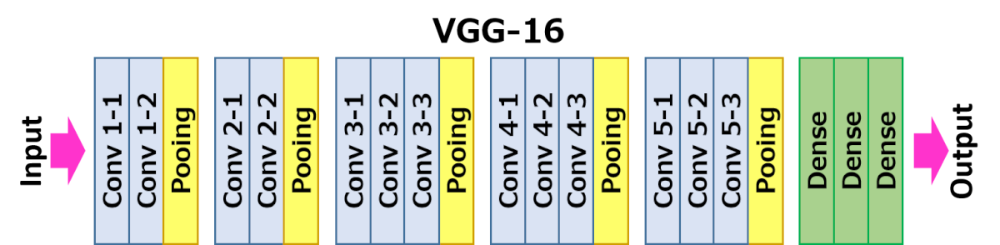
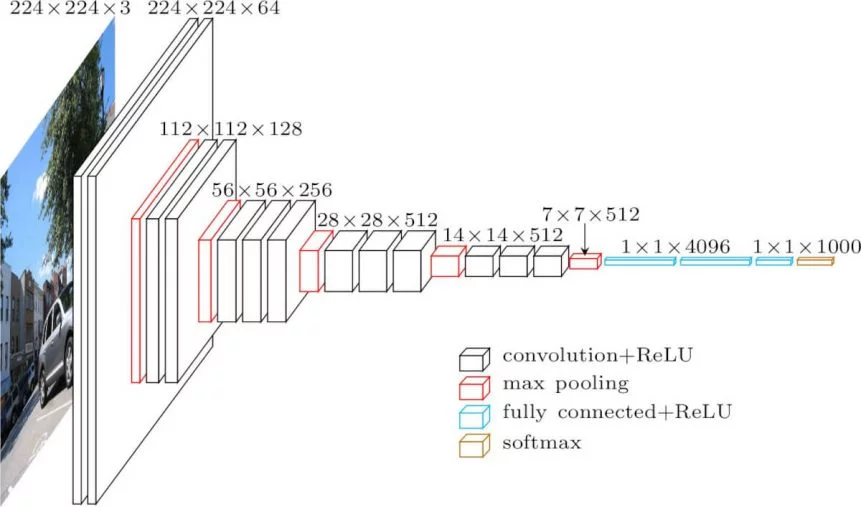
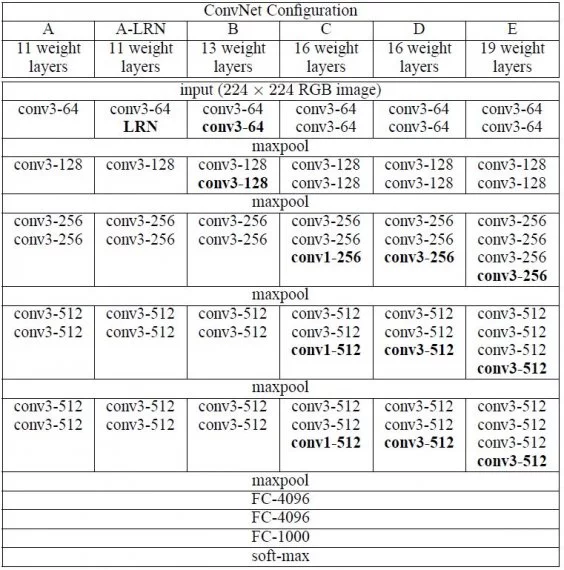

우리는 이 모델을 그대로 쓰지 않고 Transfer Learning 시킬 것이기 때문에 Dense Layer는 쓰지 않는다. 이 부분은 우리가 새로 만들어주어야 한다.

### VGG16 끝단에 classifier 레이어를 붙여서 원하는 구조의 분류 모델 만들기

In [52]:
import numpy as np

image = np.array([[1, 2],
                  [3, 4]])
                  
flattened_image = image.flatten()

print("Original image:\n", image)
print("Original image shape:", image.shape)
print()
print("Flattened image:\n", flattened_image)
print("Flattened image shape:", flattened_image.shape)

Original image:
 [[1 2]
 [3 4]]
Original image shape: (2, 2)

Flattened image:
 [1 2 3 4]
Flattened image shape: (4,)


2차원 또는 3차원 벡터를 1차원으로 축소하는 방법에는 Flattening 하는 것보다 조금 더 좋은 방법이 있다.

그 방법은 바로 Global Average Pooling이다.

**GAP의 목적은 feature를 1차원 벡터로 만들기 위함이다.**

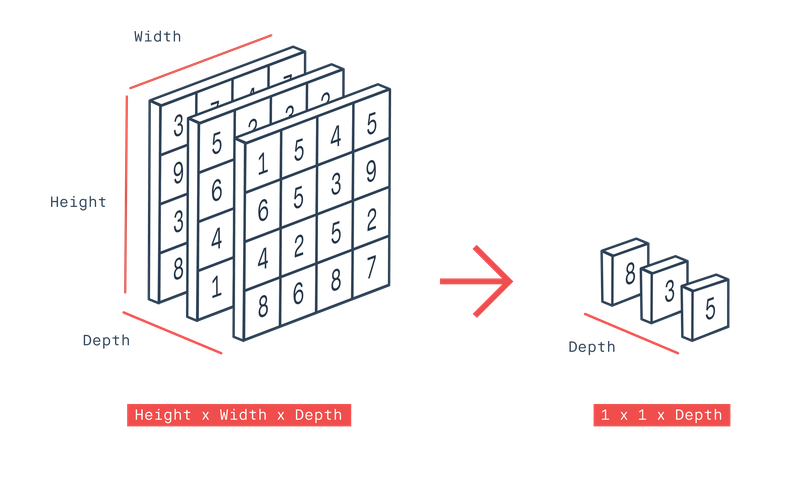

Global Average Pooling은 위와 같이 3차원의 벡터가 있을 때, 겹겹이 쌓여있는 2차원 배열의 평균을 구한 후 하나의 값으로 축소하는 기법이다.

위 그림에서는 왼쪽의 3차원 배열에서 맨 앞 장인 [[1, 5, 4, 5], ..., [8, 6, 8, 7]] 에 있는 16개 숫자의 평균을 구하면 '5'라는 숫자가 된다.

이와 같이 평균값을 활용해 벡터의 차원을 줄이는 방법 을 Global Average Pooling이라고 한다.

In [53]:
# Global Average Pooling 계층을 만드는 코드를 확인
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
print("슝~")

슝~


global_average_layer에 위에서 VGG16이 출력했던 feature_batch를 입력하면 어떻게 될까?

In [54]:
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 512)


In [55]:
# dense layer에는 unit과 activation 2개의 매개변수만 사용해주세요.
# unit의 값은 위에서 global_average_layer를 통과했을 때의 값을 생각해보세요.
# 활성화 함수는 ReLU를 사용합니다.
dense_layer = tf.keras.layers.Dense(512, activation='relu')
# unit은 우리가 분류하고 싶은 class를 생각해보세요.
# 활성화 함수는 Softmax를 사용합니다.
prediction_layer = tf.keras.layers.Dense(2, activation='softmax')

# feature_batch_averag가 dense_layer를 거친 결과가 다시 prediction_layer를 거치게 되면
prediction_batch = prediction_layer(dense_layer(feature_batch_average))  
print(prediction_batch.shape)

(32, 2)


우리의 데이터들은 처음에 이미지에서 특징을 추출해 줄 VGG16, base_model에 입력되어 특징이 추출된 다음, 그 특징 벡터는 global_average_layer를 거쳐 마지막에 prediction_layer까지 통과하며 강아지인지, 고양이인지 예측이 될 것이다.

여기에서, VGG16에 해당하는 base_model은 학습을 시키지 않을 예정이니 학습 여부를 결정하는 trainable 변수를 False로 지정해 "꺼주겠"다.

In [56]:
base_model.trainable = False
print("슝~")

슝~


In [58]:
# 최종 모델 만들기
model = tf.keras.Sequential([
    base_model, 
    global_average_layer, 
    dense_layer, 
    prediction_layer
])
print("슝~")

슝~


In [59]:
# 모델 구조 확인
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
vgg16 (Functional)           (None, 5, 5, 512)         14714688  
_________________________________________________________________
global_average_pooling2d (Gl (None, 512)               0         
_________________________________________________________________
dense_4 (Dense)              (None, 512)               262656    
_________________________________________________________________
dense_5 (Dense)              (None, 2)                 1026      
Total params: 14,978,370
Trainable params: 263,682
Non-trainable params: 14,714,688
_________________________________________________________________


### VGG16을 기반으로 구성된 이미지 분류기를 학습시키고, 직접 만들었던 모델과 결과 비교해 보기

In [65]:
# compile 코드 작성
base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=base_learning_rate),
             loss=tf.keras.losses.sparse_categorical_crossentropy,
             metrics=['accuracy'])

print("슝~")

슝~


In [66]:
# 초기 손실과 정확도 값을 확인
validation_steps=20
loss0, accuracy0 = model.evaluate(validation_batches, steps = validation_steps)

print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2f}".format(accuracy0))

 6/20 [========>.....................] - ETA: 0s - loss: 0.7704 - accuracy: 0.4271

Corrupt JPEG data: 162 extraneous bytes before marker 0xd9


18/20 [==========================>...] - ETA: 0s - loss: 0.7697 - accuracy: 0.4062

Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


20/20 [==============================] - 5s 70ms/step - loss: 0.7694 - accuracy: 0.4094
initial loss: 0.77
initial accuracy: 0.41


In [67]:
# 모델 학습
EPOCHS = 5  # 이번에는 이전보다 훨씬 빠르게 수렴되므로 5Epoch이면 충분하다.
history = model.fit(train_batches, 
                    epochs=EPOCHS,
                    validation_data=validation_batches)

Epoch 1/5
166/582 [=======>......................] - ETA: 1:01 - loss: 0.3835 - accuracy: 0.8710

Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


199/582 [=========>....................] - ETA: 56s - loss: 0.3618 - accuracy: 0.8769

209/582 [=========>....................] - ETA: 55s - loss: 0.3561 - accuracy: 0.8786

Corrupt JPEG data: 396 extraneous bytes before marker 0xd9


281/582 [=============>................] - ETA: 44s - loss: 0.3204 - accuracy: 0.8901

... (86 outputs left out)

Corrupt JPEG data: 228 extraneous bytes before marker 0xd9


582/582 [==============================] - ETA: 0s - loss: 0.1342 - accuracy: 0.9454

Corrupt JPEG data: 162 extraneous bytes before marker 0xd9
Corrupt JPEG data: 252 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


582/582 [==============================] - 55s 92ms/step - loss: 0.1342 - accuracy: 0.9454 - val_loss: 0.1374 - val_accuracy: 0.9424


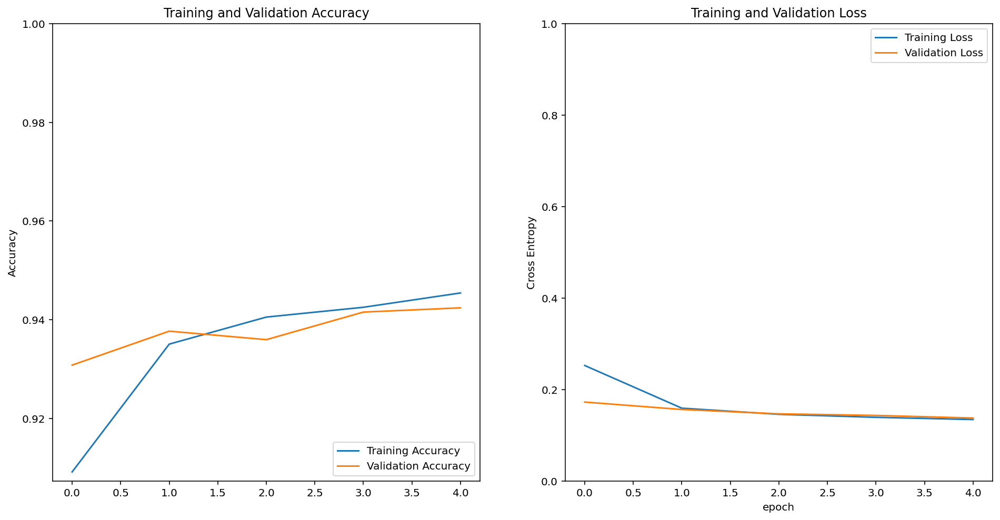

In [68]:
# 그래프로 학습 과정 시각화
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

우리가 직접 만들었던 모델과는 다르게 시작부터 75%를 넘는 정확도에서 꾸준히 올라갈뿐더러 validation loss도 매우 안정적으로 학습된다.

In [69]:
# 32개의 test sample에 대한 예측 결과
for image_batch, label_batch in test_batches.take(1):
    images = image_batch
    labels = label_batch
    predictions = model.predict(image_batch)
    pass

predictions

array([[9.9999249e-01, 7.5141252e-06],
       [1.1018738e-01, 8.8981265e-01],
       [2.6312912e-01, 7.3687088e-01],
       [9.9999654e-01, 3.4852412e-06],
       [9.9811327e-01, 1.8867096e-03],
       [9.8672915e-01, 1.3270852e-02],
       [1.2706386e-04, 9.9987292e-01],
       [6.9943923e-01, 3.0056080e-01],
       [9.4745368e-01, 5.2546360e-02],
       [9.6590239e-01, 3.4097679e-02],
       [6.7562207e-05, 9.9993241e-01],
       [9.9994934e-01, 5.0666651e-05],
       [9.8760158e-01, 1.2398367e-02],
       [4.8412680e-06, 9.9999511e-01],
       [9.9864024e-01, 1.3596986e-03],
       [9.8326451e-01, 1.6735489e-02],
       [9.9596256e-01, 4.0374873e-03],
       [2.8054424e-02, 9.7194564e-01],
       [6.6931432e-01, 3.3068568e-01],
       [9.9565697e-01, 4.3430254e-03],
       [9.1906452e-01, 8.0935515e-02],
       [9.8053563e-01, 1.9464346e-02],
       [9.9399865e-01, 6.0013994e-03],
       [9.7405452e-01, 2.5945460e-02],
       [9.9822825e-01, 1.7717285e-03],
       [9.8334366e-01, 1.

In [70]:
# prediction 값들을 실제 추론한 라벨(고양이:0, 강아지:1)로 변환
import numpy as np
predictions = np.argmax(predictions, axis=1)
predictions

array([0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0])

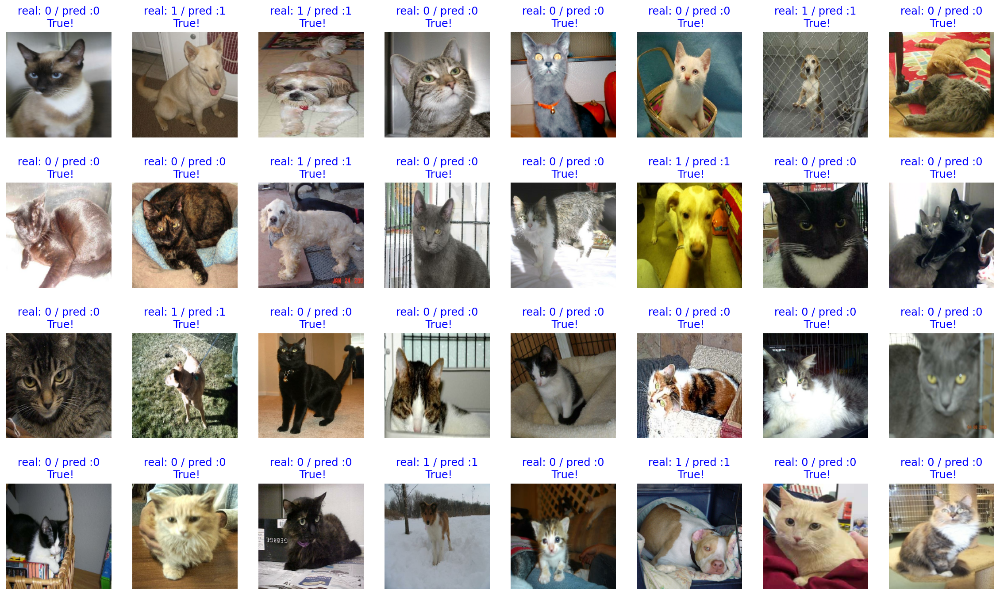

In [71]:
plt.figure(figsize=(20, 12))

for idx, (image, label, prediction) in enumerate(zip(images, labels, predictions)):
    plt.subplot(4, 8, idx+1)
    image = (image + 1) / 2
    plt.imshow(image)
    correct = label == prediction
    title = f'real: {label} / pred :{prediction}\n {correct}!'
    if not correct:
        plt.title(title, fontdict={'color': 'red'})
    else:
        plt.title(title, fontdict={'color': 'blue'})
    plt.axis('off')

아까보다 훨씬 잘 맞추는 것을 볼 수 있다. 이번에도 32개에 대한 정확도를 확인해보자.

In [72]:
count = 0
for image, label, prediction in zip(images, labels, predictions):
    correct = label == prediction
    if correct:
        count = count + 1

print(count / 32 * 100) # 약 95% 내외

100.0


### 모델을 save 하고, 다시 load 해와서 사용하는 방법 익히기

자, 이제 우리가 많은 시간과 노력을 들여서 모델을 학습시켰으니, 저장하는 법을 알아보자.

열심히 학습시켜서 한 번만 쓰기에는 아깝다! 저장해두고 언제든 다시 쓸 수 있다면 좋겠다.

모델을 저장하는 법은 생각보다 아주 간단하다.

다음과 같이 save_weights 함수를 활용한다. 파라미터로 저장하고 싶은 경로만 입력해주면 된다.

다음과 같이 ./checkpoint/checkpoint 라는 경로로 저장하게 되면 현재 위치에 있는 checkpoint라는 폴더 내에 checkpoint라는 파일명으로 저장된다.

단, checkpoint 폴더가 존재하지 않는다면 에러가 발생하므로, 다음과 같이 터미널을 열어 해당 폴더를 만들어주는 것이 안전하다.

물론 다른 경로에, 다른 이름으로 저장해도 된다.

In [73]:
!mkdir -p ~/aiffel/cat_vs_dog/checkpoint
!mkdir -p ~/aiffel/cat_vs_dog/images

In [74]:
import os

checkpoint_dir = os.getenv("HOME") + "/aiffel/cat_vs_dog/checkpoint"
checkpoint_file_path = os.path.join(checkpoint_dir, 'checkpoint')

if not os.path.exists('checkpoint_dir'):
    os.mkdir('checkpoint_dir')
    
model.save_weights(checkpoint_file_path)     # checkpoint 파일 생성

if os.path.exists(checkpoint_file_path):
  print('checkpoint 파일 생성 OK!!')

checkpoint 파일 생성 OK!!


### 학습된 모델에 원하는 이미지를 입력해 예측 결과 확인해 보기

프리픽(Freepik)에서 구해온 강아지와 고양이의 이미지를 넣어보도록 하자. 아래 명령어를 통해 준비된 이미지를 연결한다.

In [75]:
!ln -s ~/data/* ~/aiffel/cat_vs_dog/images/

ln: failed to create symbolic link '/aiffel/aiffel/cat_vs_dog/images/cat_face.jpg': File exists
ln: failed to create symbolic link '/aiffel/aiffel/cat_vs_dog/images/cats_vs_dogs': File exists
ln: failed to create symbolic link '/aiffel/aiffel/cat_vs_dog/images/my_cat.jpg': File exists
ln: failed to create symbolic link '/aiffel/aiffel/cat_vs_dog/images/my_dog.jpg': File exists


In [76]:
# tensorflow 모델에 입력해주기 위해 load_img, img_to_array 함수를 가져온다.
from tensorflow.keras.preprocessing.image import load_img, img_to_array

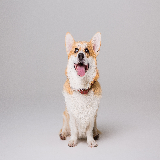

In [77]:
# (160, 160) 사이즈만 입력받을 수 있기 때문에 파라미터로 이미지 사이즈를 넣어준다.
IMG_SIZE = 160
img_dir_path = os.getenv("HOME") + "/aiffel/cat_vs_dog/images"
dog_image_path = os.path.join(img_dir_path, 'my_dog.jpg')

dog_image = load_img(dog_image_path, target_size=(IMG_SIZE, IMG_SIZE))
dog_image

In [78]:
# 모델에 넣을 수 있도록 이미지를 array, 즉 배열 자료형으로 변환
dog_image = img_to_array(dog_image).reshape(1, IMG_SIZE, IMG_SIZE, 3)
dog_image.shape

(1, 160, 160, 3)

In [79]:
# 이미지를 모델에 넣어 예측, 고양이라면 [1.0, 0.0], 강아지라면 [0.0, 1.0]에 가까운 확률 분포가 예측된다.
prediction = model.predict(dog_image)
prediction

array([[4.4579712e-15, 1.0000000e+00]], dtype=float32)

In [80]:
# 위의 과정을 함수로 만들어 원하는 이미지를 자유자재로 예측
def show_and_predict_image(dirpath, filename, img_size=160):
    filepath = os.path.join(dirpath, filename)
    image = load_img(filepath, target_size=(img_size, img_size))
    plt.imshow(image)
    plt.axis('off')
    image = img_to_array(image).reshape(1, img_size, img_size, 3)
    prediction = model.predict(image)[0]
    cat_percentage = round(prediction[0] * 100)
    dog_percentage = round(prediction[1] * 100)
    print(f"This image seems {dog_percentage}% dog, and {cat_percentage}% cat.")

This image seems 100% dog, and 0% cat.


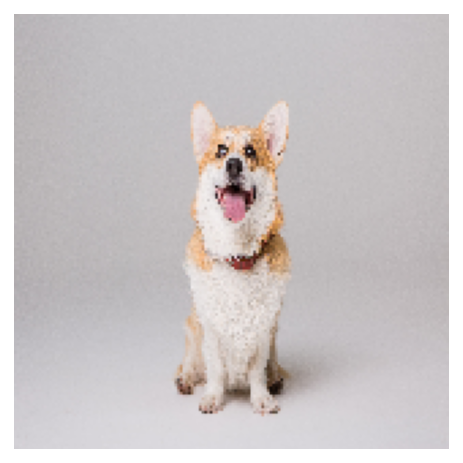

In [81]:
# 강아지 이미지를 함수에 넣어보자.
filename = 'my_dog.jpg'

show_and_predict_image(img_dir_path, filename)

This image seems 0% dog, and 100% cat.


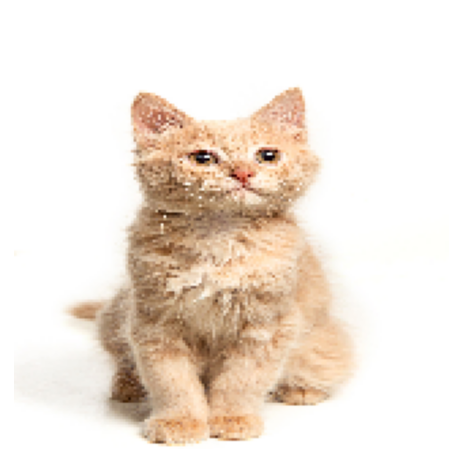

In [82]:
# 고양이를 예측해보자
filename = 'my_cat.jpg'

show_and_predict_image(img_dir_path, filename)

This image seems 100% dog, and 0% cat.


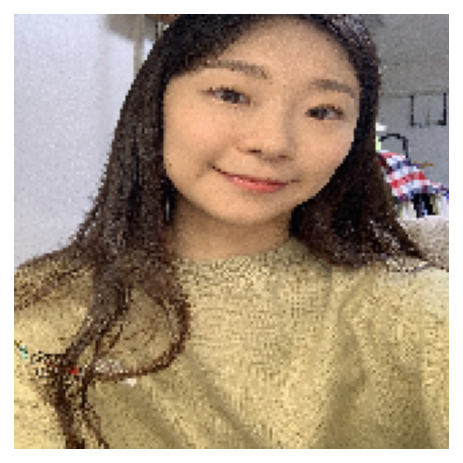

In [83]:
# 내 얼굴 예측하기
filename = "itsme.jpg"
show_and_predict_image(img_dir_path, filename)

In [ ]:
raw.train.shape